<a href="https://colab.research.google.com/github/ldnetak/ldnetak.github.io/blob/main/02_QuantumCircuit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 2. Your First Quantum Circuit

In this notebook we build a quantum circuit step by step, explaining every line, and run it on IBM's Aer simulator.

A quantum circuit is built from:

    a) qubits (quantum bits) — start in state |0>
    b) gates — operations that change the qubit's state
    c) measurements — read out a classical 0 or 1 from a qubit

# Step 1: Import libraries

In [2]:
!pip install qiskit qiskit-aer matplotlib pylatexenc

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_distribution, plot_histogram



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 74.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 80.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 66.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [qiskit-aer]


# Step 2: Create a circuit with 1 qubit and 1 classical bit

The classical bit is where we will store the measurement result.

In [3]:
qc = QuantumCircuit(1, 1)
print(qc.draw("text"))

     
  q: 
     
c: 1/
     


# Step 3: Apply a Hadamard (H) gate

The Hadamard gate puts qubit 0 into an equal superposition of |0> and |1> — before measurement, it is "both at once".

In [4]:
qc.h(0)
print(qc.draw("text"))

     ┌───┐
  q: ┤ H ├
     └───┘
c: 1/═════
          


# Step 4: Draw the circuit diagram

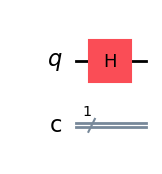

In [5]:
qc.draw("mpl")

# Step 5: Check the exact state before measurement

Probabilities: {np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


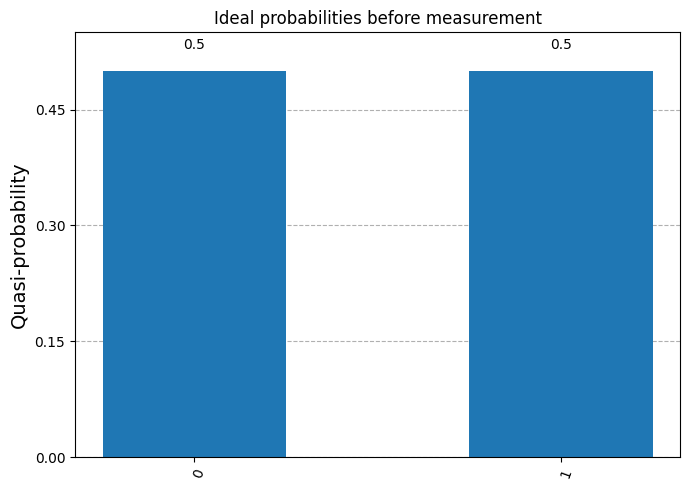

In [6]:
state = Statevector(qc)
probabilities = state.probabilities_dict()
print("Probabilities:", probabilities)

plot_distribution(probabilities, title="Ideal probabilities before measurement")

# Step 6: Add a measurement

qc.measure(0, 0) means: measure qubit 0 and store the result in classical bit 0

In [7]:
qc.measure(0, 0)
print(qc.draw("text"))

     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


# Step 7: Run the circuit on the Aer-simulator

shots=1024 means we repeat the whole experiment 1024 times and count how often we get each result.

In [8]:
simulator = AerSimulator()
compiled_circuit = transpile(qc, simulator)
job = simulator.run(compiled_circuit, shots=1024)
result = job.result()
counts = result.get_counts()

print("Measurement counts:", counts)

Measurement counts: {'1': 521, '0': 503}


# Step 8: Plot the results as a histogram

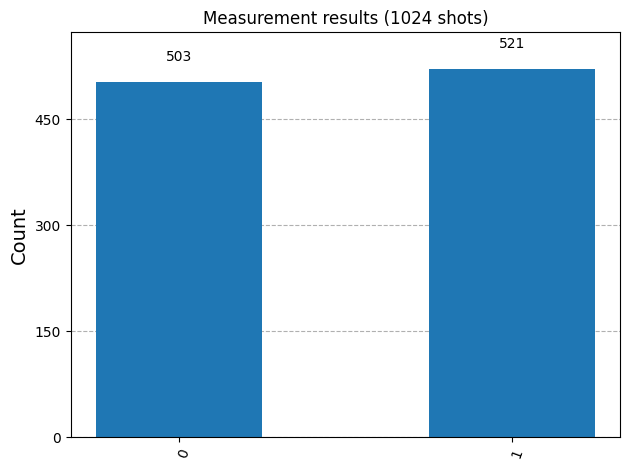

In [9]:
plot_histogram(counts, title="Measurement results (1024 shots)")